<a href="https://colab.research.google.com/github/MNawfal24/MachineLearning/blob/main/Minggu11/MNawfalMA_JS11_P03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [2]:
# Create function to visualize SVM decision function
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Create grid for model evaluation
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot decision boundary and margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1.5, facecolors='none', edgecolors='black');

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

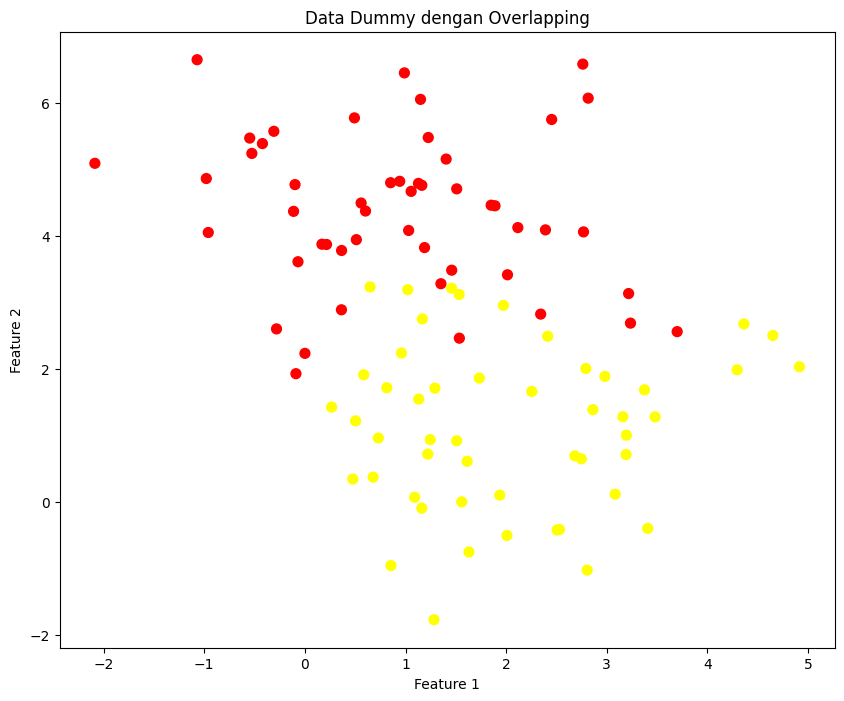

Perhatikan bahwa ada beberapa titik yang tumpang tindih antara dua kelas!


In [3]:
# Create overlapping data with larger cluster_std
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)

plt.figure(figsize=(10, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Data Dummy dengan Overlapping')
plt.show()

print('Perhatikan bahwa ada beberapa titik yang tumpang tindih antara dua kelas!')

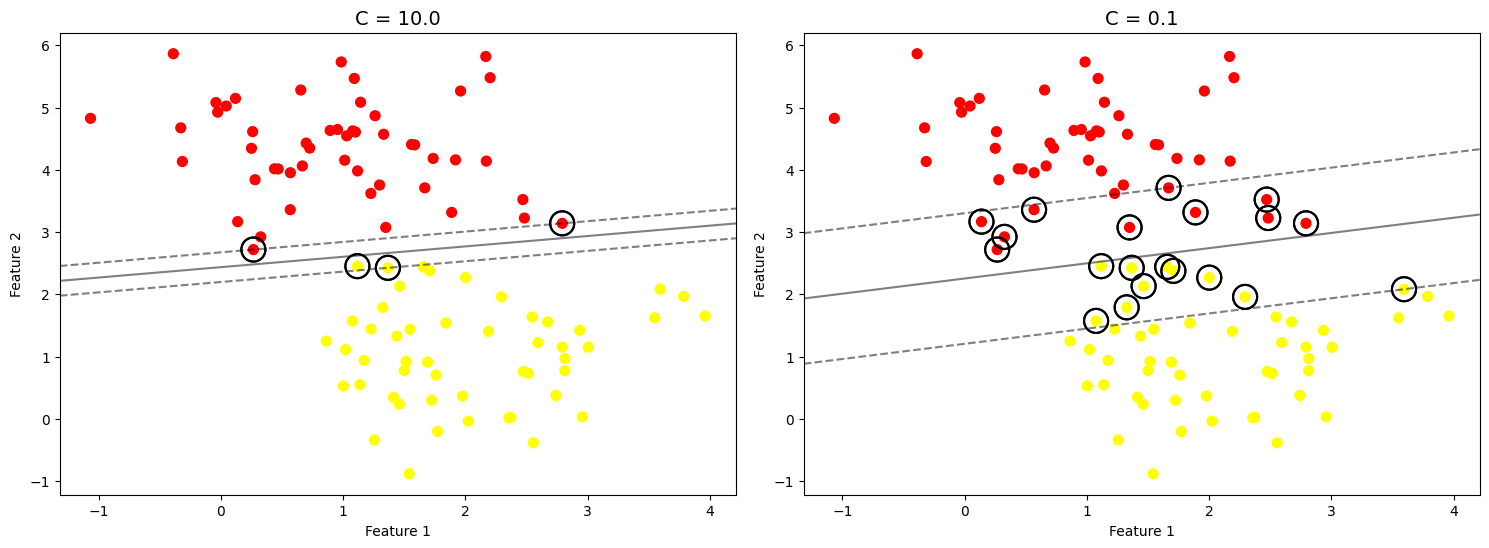


Penjelasan Parameter C:
- C besar (10.0): Margin lebih sempit, lebih sedikit misklasifikasi (hard margin)
- C kecil (0.1): Margin lebih lebar, toleran terhadap misklasifikasi (soft margin)


In [4]:
# Recreate data with different cluster_std for better visualization
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

# Compare different C values
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1.5, facecolors='none', edgecolors='black');
    axi.set_title(f'C = {C:.1f}', size=14)
    axi.set_xlabel('Feature 1')
    axi.set_ylabel('Feature 2')

plt.show()

print('\nPenjelasan Parameter C:')
print('- C besar (10.0): Margin lebih sempit, lebih sedikit misklasifikasi (hard margin)')
print('- C kecil (0.1): Margin lebih lebar, toleran terhadap misklasifikasi (soft margin)')